# Headline figure
One graph for a non-specialist, used in both the video and the article. Run notebooks 01–05 first.
Score: hypoxia-only genes (Hallmark hypoxia minus genes shared with glycolysis), as pre-specified for replication.

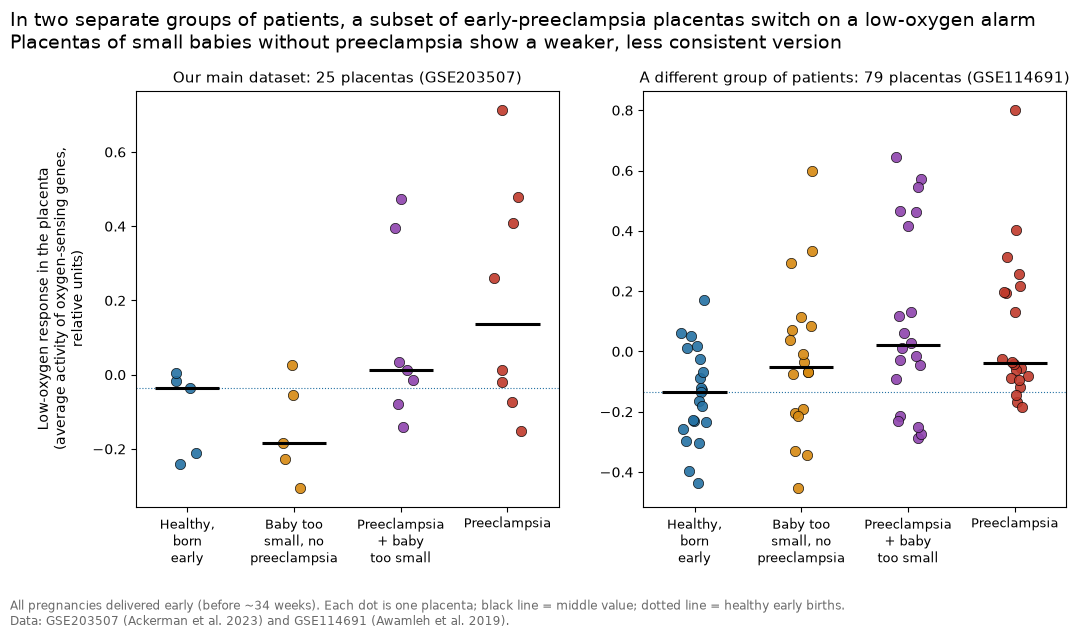

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pydeseq2.dds import DeseqDataSet
from pydeseq2.default_inference import DefaultInference

ROOT = Path(".."); FIG_DIR = ROOT / "figures"; RES_DIR = Path("results")
DATA_DIR = ROOT / "openbio-datathon-2026" / "track-01" / "data"
gmt = {l.split("\t")[0]: l.rstrip("\n").split("\t")[2:] for l in open(ROOT / "data_external" / "h.all.v2024.1.Hs.symbols.gmt")}
HYP_ONLY = set(gmt["HALLMARK_HYPOXIA"]) - set(gmt["HALLMARK_GLYCOLYSIS"])

counts = pd.read_csv(DATA_DIR / "track01_counts_vt.csv", index_col=0)
meta = pd.read_csv(DATA_DIR / "track01_metadata_vt.csv", index_col=0).loc[counts.columns]
counts = counts.loc[(counts >= 10).sum(axis=1) >= 5]
dds = DeseqDataSet(counts=counts.T.astype(int), metadata=meta[["pe_status"]], design="~pe_status",
                   inference=DefaultInference(n_cpus=4), quiet=True)
dds.fit_size_factors(); dds.vst(use_design=False)
vst = pd.DataFrame(dds.layers["vst_counts"], index=counts.columns, columns=counts.index)
z = (vst - vst.mean()) / vst.std()
disc = pd.DataFrame({"score": z[sorted(g for g in HYP_ONLY if g in z.columns)].mean(axis=1), "group": meta.group})
disc = disc[disc.group != "TB"]
rep = pd.read_csv(RES_DIR / "C1_scores_GSE114691.csv", index_col=0)[["hyp_only", "group"]].rename(columns={"hyp_only": "score"})
rep["group"] = rep.group.map({"control": "iPTB", "IUGR": "FGR", "PE+IUGR": "EOPE+FGR", "PE": "EOPE"})

order = [("iPTB", "Healthy,\nborn\nearly", "#2471a3"), ("FGR", "Baby too\nsmall, no\npreeclampsia", "#d68910"),
         ("EOPE+FGR", "Preeclampsia\n+ baby\ntoo small", "#8e44ad"), ("EOPE", "Preeclampsia", "#c0392b")]
rng = np.random.default_rng(3)
fig, axes = plt.subplots(1, 2, figsize=(12, 5.4), sharey=False)
for ax, (tab, title) in zip(axes, [(disc, "Our main dataset: 25 placentas (GSE203507)"),
                                   (rep, "A different group of patients: 79 placentas (GSE114691)")]):
    for i, (g, lab, col) in enumerate(order):
        v = tab.loc[tab.group == g, "score"]
        ax.scatter(i + rng.uniform(-0.13, 0.13, len(v)), v, s=55, c=col, edgecolor="k", lw=0.5, zorder=3, alpha=0.9)
        ax.hlines(v.median(), i - 0.3, i + 0.3, color="k", lw=2.2, zorder=4)
    ax.axhline(tab.loc[tab.group == "iPTB", "score"].median(), c="#2471a3", lw=0.8, ls=":")
    ax.set_xticks(range(4)); ax.set_xticklabels([o[1] for o in order], fontsize=9.5)
    ax.set_title(title, fontsize=10.5)
axes[0].set_ylabel("Low-oxygen response in the placenta\n(average activity of oxygen-sensing genes,\nrelative units)", fontsize=10)
fig.suptitle("In two separate groups of patients, a subset of early-preeclampsia placentas switch on a low-oxygen alarm\n"
             "Placentas of small babies without preeclampsia show a weaker, less consistent version",
             fontsize=13.5, x=0.02, ha="left", y=1.03)
fig.text(0.02, -0.06, "All pregnancies delivered early (before ~34 weeks). Each dot is one placenta; black line = middle value; dotted line = healthy early births.\n"
         "Data: GSE203507 (Ackerman et al. 2023) and GSE114691 (Awamleh et al. 2019).", fontsize=8.5, color="dimgrey", va="top")
plt.savefig(FIG_DIR / "fig0_group_scores.png", dpi=300, bbox_inches="tight"); plt.show()